# RetailPulse — Exploratory Data Analysis

## Objective
Explore the Online Retail dataset, understand its structure,
identify data-quality issues, and discover initial business patterns.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/raw/Online Retail.xlsx")

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [6]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

print("Duplicate percentage:",
      round(duplicate_count / len(df) * 100, 2), "%")

Total duplicate records: 5268
Duplicate percentage: 0.97 %


In [7]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

print("Total transaction period:",
      (df["InvoiceDate"].max() - df["InvoiceDate"].min()).days,
      "days")

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00
Total transaction period: 373 days


In [8]:
df["Quantity"].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

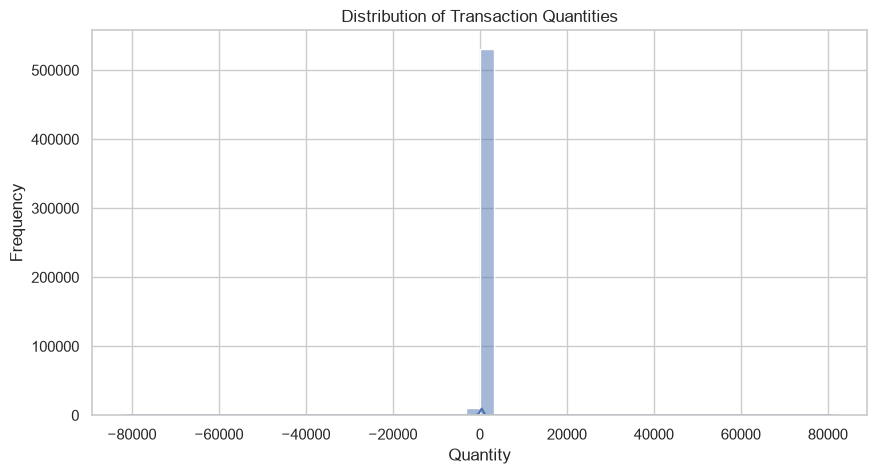

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Quantity"],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

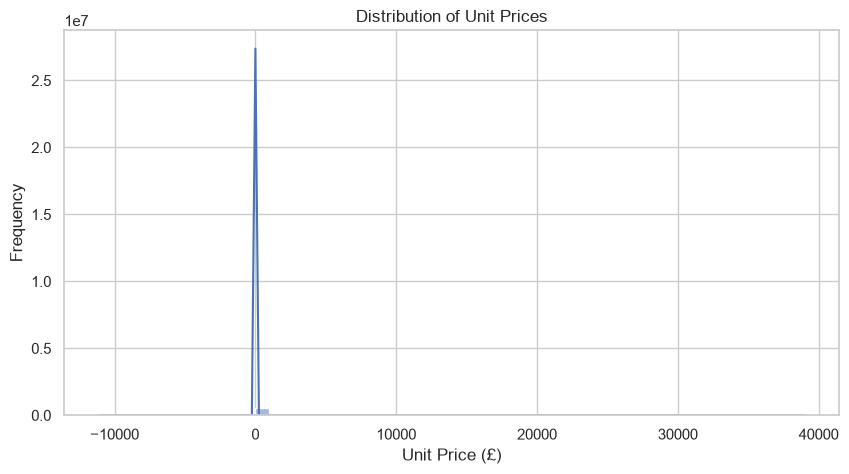

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["UnitPrice"],
    bins=50,
    kde=True
)

plt.title("Distribution of Unit Prices")
plt.xlabel("Unit Price (£)")
plt.ylabel("Frequency")

plt.show()

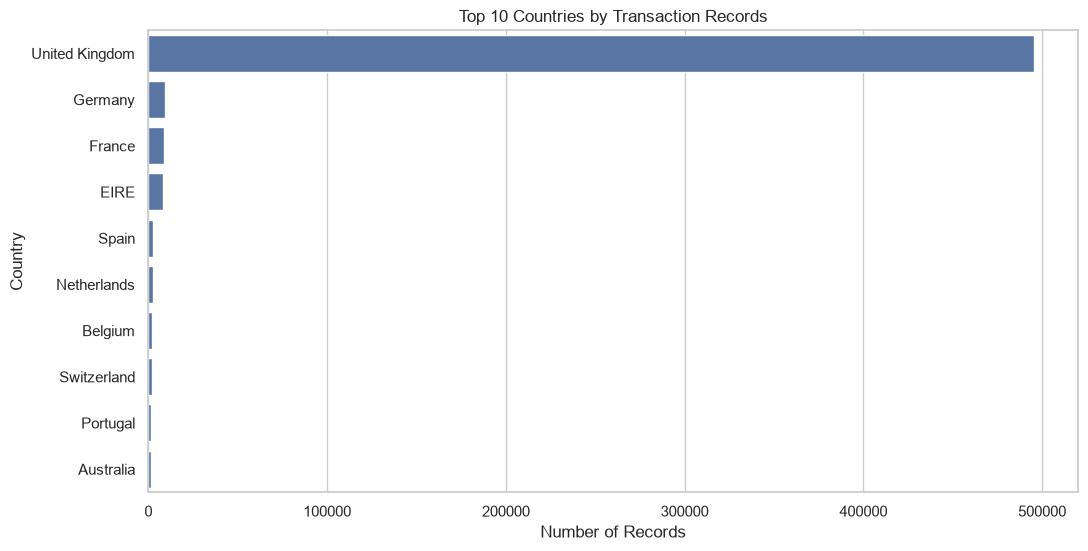

In [11]:
country_transactions = (
    df["Country"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_transactions.values,
    y=country_transactions.index
)

plt.title("Top 10 Countries by Transaction Records")
plt.xlabel("Number of Records")
plt.ylabel("Country")

plt.show()

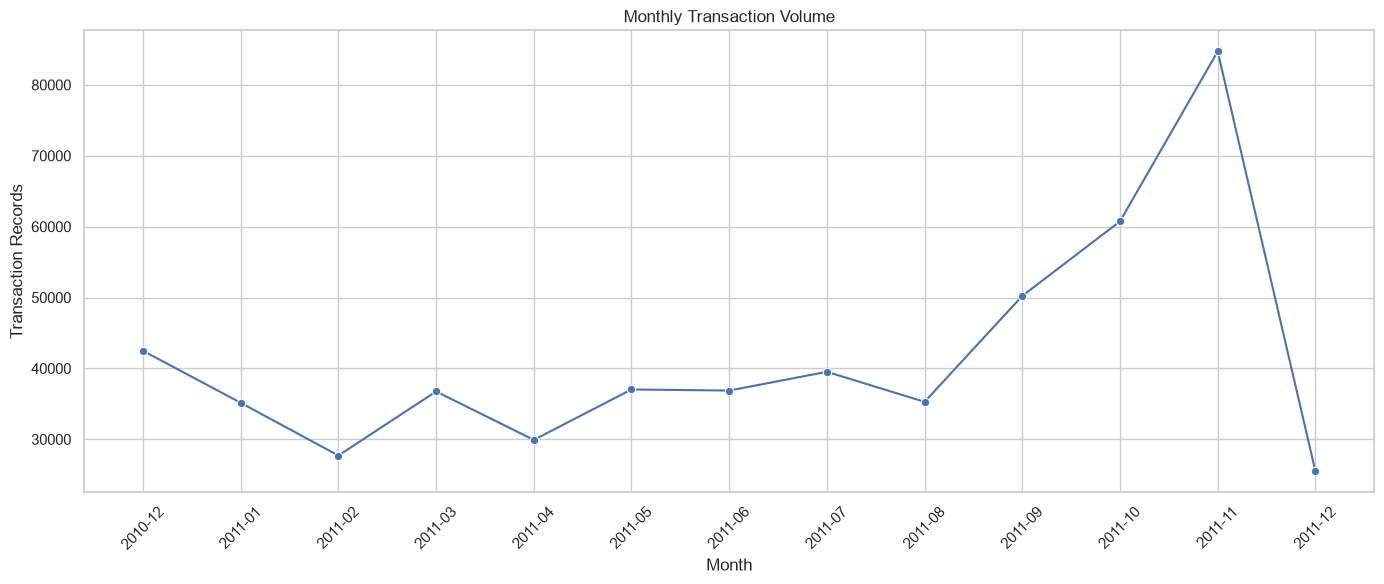

In [12]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)

monthly_transactions = (
    df.groupby("YearMonth")
    .size()
    .reset_index(name="Transaction Records")
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_transactions,
    x="YearMonth",
    y="Transaction Records",
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Transaction Records")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Records",
        "Missing Customer IDs",
        "Missing Descriptions",
        "Unique Countries",
        "Unique Products"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df["CustomerID"].isna().sum(),
        df["Description"].isna().sum(),
        df["Country"].nunique(),
        df["StockCode"].nunique()
    ]
})

eda_summary.to_csv(
    "../reports/eda_summary.csv",
    index=False
)

eda_summary

,Metric,Value
0,Total Records,541909
1,Total Columns,9
2,Duplicate Records,5268
3,Missing Customer IDs,135080
4,Missing Descriptions,1454
5,Unique Countries,38
6,Unique Products,4070
